In [1]:
!pip install roboflow ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 21.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="")
project = rf.workspace("yaseradel02s-workspace").project("arabic-food-ts9cg")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Arabic-Food-1 in yolo26:: 100%|██████████| 4517/4517 [00:00<00:00, 7051.10it/s]


In [3]:
from ultralytics import YOLO

model = YOLO("yolo26l.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model.train(data='/content/Arabic-Food-1/data.yaml', epochs=10)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Arabic-Food-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opti

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c3e32617b60>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.

In [5]:
finetuned_model = YOLO('/content/runs/detect/train/weights/best.pt')

In [16]:
results = finetuned_model('/content/Arabic-Food-1/valid/images/007_asidah-dates_jpg.rf.714831c7b3200225adee8fc7be514078.jpg')


image 1/1 /content/Arabic-Food-1/valid/images/007_asidah-dates_jpg.rf.714831c7b3200225adee8fc7be514078.jpg: 640x640 1 Asidah, 74.9ms
Speed: 2.0ms preprocess, 74.9ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)


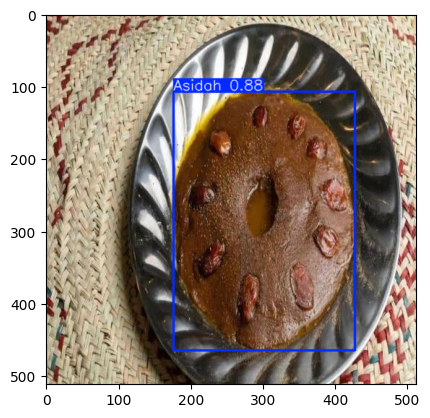

In [17]:
import matplotlib.pyplot as plt

plt.imshow(results[0].plot()[..., ::-1]);

In [20]:
from ultralytics import YOLO

model = YOLO("/content/runs/detect/train/weights/best.pt")


metrics = model.val(
    data="/content/Arabic-Food-1/data.yaml",
    split="val",
    plots=True
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.202 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26l summary (fused): 188 layers, 24,754,221 parameters, 0 gradients, 86.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1513.9±544.2 MB/s, size: 30.7 KB)
val: Scanning /content/Arabic-Food-1/valid/labels.cache... 77 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 77/77 23.1Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 8, len(boxes) = 92. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.1it/s 4.6s
                   all         77         92      0.818      0.829      0.871      0.639
                Asidah          6          6      0.696      0.667       0.85      0.672
               Falafel          3       

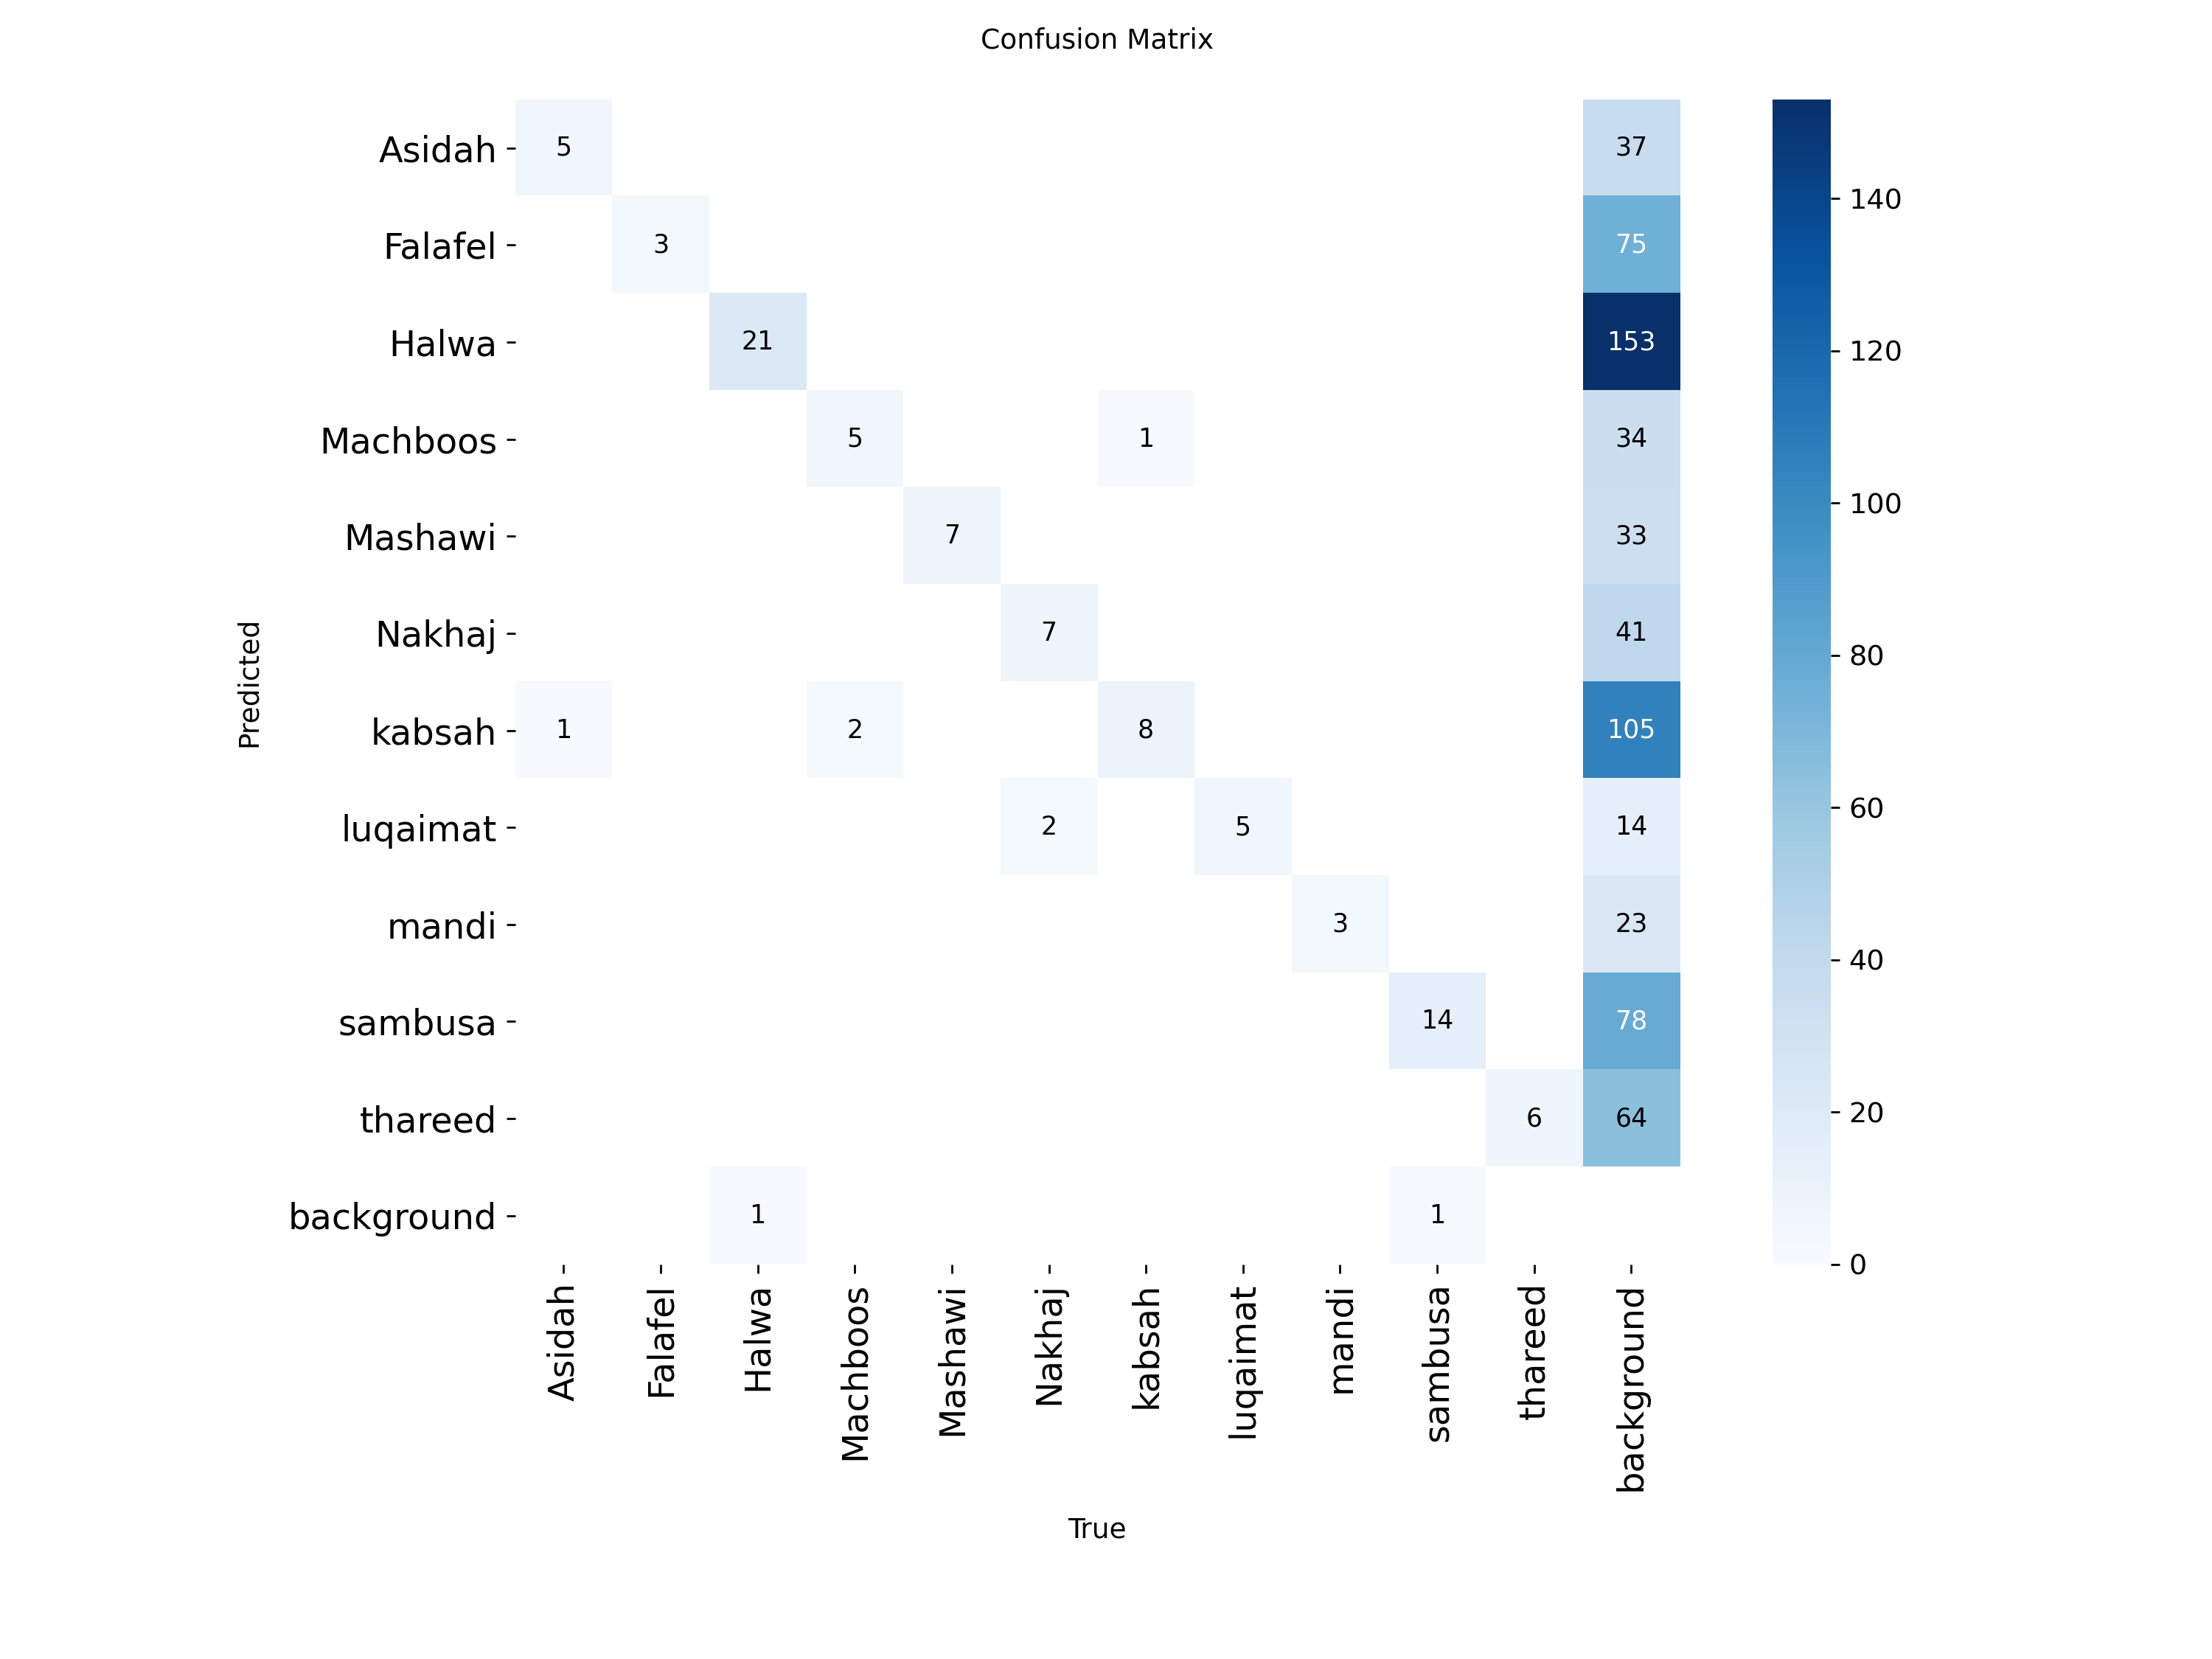

In [21]:
from IPython.display import Image, display

display(Image(
    filename=str(metrics.save_dir / "confusion_matrix.png")
))

In [22]:
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")

results = model.predict(
    source="/content/Arabic-Food-1/valid/images",
    conf=0.25,
    save=True
)


image 1/77 /content/Arabic-Food-1/valid/images/-14-_png.rf.28147e2c059738a2a70be3bd5683e48e.jpg: 640x640 1 Falafel, 64.3ms
image 2/77 /content/Arabic-Food-1/valid/images/-181-_png.rf.553cc309625bf37813c9f558e789cf9d.jpg: 640x640 1 mandi, 54.3ms
image 3/77 /content/Arabic-Food-1/valid/images/-191-_png.rf.8a12f9528db96ab4a33b395430768be7.jpg: 640x640 1 mandi, 54.3ms
image 4/77 /content/Arabic-Food-1/valid/images/-196-_png.rf.9d27eb39dda2f1eabd287a6d28ecd6fb.jpg: 640x640 1 mandi, 51.7ms
image 5/77 /content/Arabic-Food-1/valid/images/-24-_png.rf.39a72f1e54aa31e9f97e051f0b55ce9b.jpg: 640x640 1 Falafel, 45.0ms
image 6/77 /content/Arabic-Food-1/valid/images/-36-_png.rf.3563429ad2683f54d80e79a4afb9bcef.jpg: 640x640 1 Falafel, 43.1ms
image 7/77 /content/Arabic-Food-1/valid/images/002_makaruna-bechamel-sambusa-maybedates_jpg.rf.54cf80e2ae99bbfe75b34c71cf816d75.jpg: 640x640 1 kabsah, 2 sambusas, 45.8ms
image 8/77 /content/Arabic-Food-1/valid/images/007_asidah-dates_jpg.rf.714831c7b3200225adee8fc

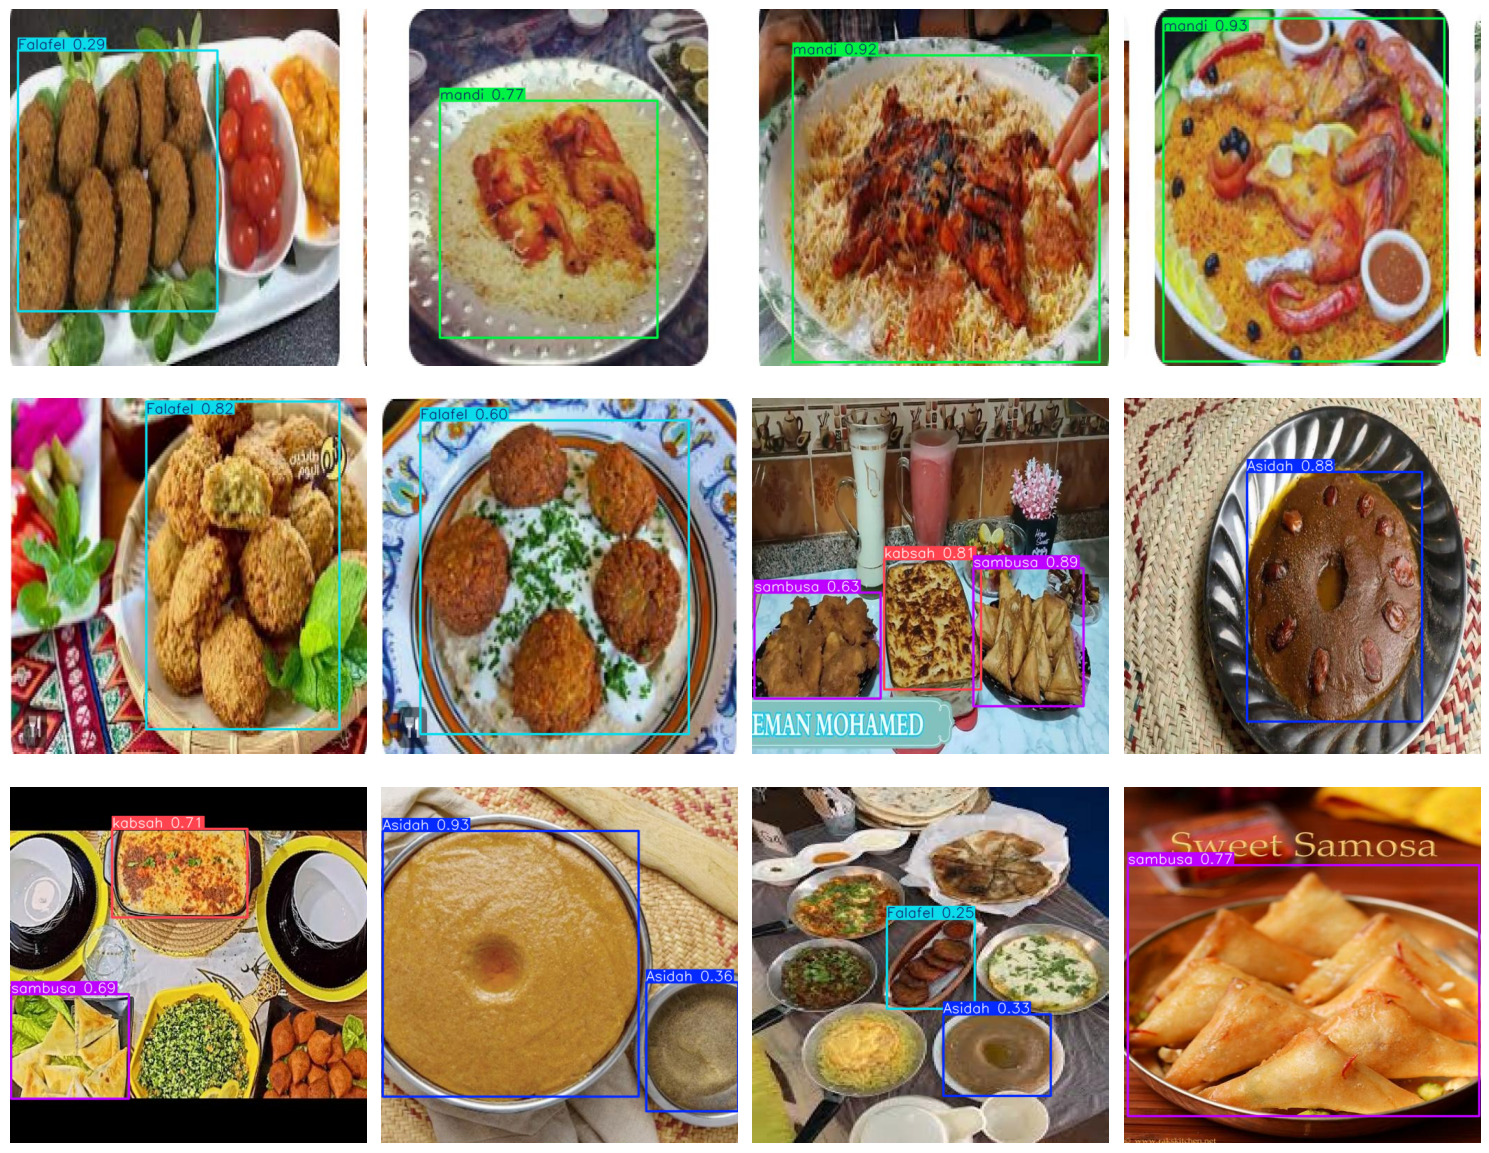

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 12))

for i in range(min(12, len(results))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(results[i].plot()[..., ::-1])
    plt.axis("off")

plt.tight_layout()
plt.show()